Examen finale: Sahel Mobile
Sahel Mobile : analyse de la résiliation des abonnés
Sahel Mobile est un opérateur de télécommunications comptant plus de 7 000 abonnés. Plus d'un quart d'entre eux résilient.
Nous devons comprendre qui résilie, à quel moment et pourquoi, puis construire un tableau de bord interactif pour les chefs de produit.

In [1]:
!pip install pandas numpy matplotlib seaborn streamlit plotly

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 25.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 43.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Q1.1 Chargez le fichier data/Projet_2_Sahel_Mobile.csv dans un
DataFrame nommé df.

In [ ]:
 # Acces Googledrive
from google.colab import drive
drive.mount('/content/drive')
import os
print('📁 Répertoire actuel :', os.getcwd())
print('📄 Fichiers présents :', os.listdir('/content/drive/MyDrive/Colab Notebooks/Data'))
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Data/projet2_telco_churn.csv')
df_brut = df.copy()
print(f"✅ Dataset chargé : {df.shape[0]} lignes × {df.shape[1]} colonnes")
df.head()

J’ai chargé les 7 043 abonnés dans un DataFrame df. Chaque ligne est un abonné et chaque colonne une information. La colonne Churn indique s’il a résilié

Q1.2 Vérifions le type de chaque colonne

In [ ]:
df.info()

TotalCharges est stockée en texte alors que c'est un montant, ce qui empêche tout calcul, et SeniorCitizen` est codée en 0/1 alors que les autres colonnes Oui/Non utilisent "Yes"/"No".

Partie 2_Diagnostic qualité et nettoyage

Q2.1 Valeurs manquantes

Je vérifie les valeurs manquantes parce qu’une case vide peut fausser une moyenne ou faire planter un calcul

In [ ]:
df.isnull().sum()

Problème 1. TotalCharges devrait etre en nombre pas en texte

In [ ]:
lignes_aberrantes = df_brut[df_brut["TotalCharges"].str.strip() == ""]
print(f"Nombre de lignes aberrantes : {len(lignes_aberrantes)}")
print("Valeurs de tenure pour ces lignes :", lignes_aberrantes["tenure"].unique())
print(lignes_aberrantes)

In [ ]:
print(lignes_aberrantes[["customerID", "tenure", "TotalCharges"]])

TotalCharges contient 11 cases vides que isnull()` ne détecte pas, et ces 11 abonnés ont tous une ancienneté de 0 mois : ils viennent de s'inscrire et n'ont pas encore été facturés. Je ne les supprime pas et je remplace la case vide par 0



In [ ]:
df["TotalCharges"] = df["TotalCharges"].str.strip().replace("", "0").astype(float)
df["TotalCharges"].dtype

Problème 2: Senior citizen codé 0 alors que les autres colonnes oui/non utilisent "Yes"/"No". Je l'ai convertie (0 devient "No", 1 devient "Yes") pour harmoniser



In [ ]:
df["SeniorCitizen"].unique()

In [ ]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

In [ ]:
df["SeniorCitizen"].unique()

Problèmes d'option au niveau des colonnes

In [ ]:
df["OnlineSecurity"].unique()

In [ ]:
colonnes_options = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                     "TechSupport", "StreamingTV", "StreamingMovies", "MultipleLines"]
for col in colonnes_options:
    df[col] = df[col].replace({"No internet service": "No", "No phone service": "No"})
    print(f"{col:18s}", sorted(df[col].unique()))

J’ai fait une liste des 7 colonnes concernées. Pour chacune, j’ai remplacé “No internet service” et “No phone service” par “No”, puis j’ai vérifié qu’il ne restait que “No” et “Yes”

In [ ]:
df["OnlineSecurity"].unique()

Vérifions les doublons

Lignes entièrement identiques

In [ ]:
nb_doublons=df.duplicated().sum()
print(f'il y a des lignes dupliquées: {nb_doublons}')

Identifiants clients répétés : un abonné ne doit apparaître qu'une fois


In [ ]:
print("customerID dupliqués :", df["customerID"].duplicated().sum())

Aucune ligne dupliquée et aucun customerIDen double : chaque abonné apparaît une seule fois. Aucune suppression n'était nécessaire

Analyse globale: Vérification

In [ ]:
print("TotalCharges type     :", df["TotalCharges"].dtype)
print("SeniorCitizen valeurs :", df["SeniorCitizen"].unique())
print("Valeurs manquantes    :", df.isnull().sum().sum())
print("Doublons              :", df.duplicated().sum())

## Partie 3 : Analyse descriptive et visualisation

### 3.1 Taux de résiliation global

In [ ]:
taux_churn = (df["Churn"] == "Yes").mean()
print(f"Taux de résiliation global : {taux_churn:.1%}")
print(f"Abonnés partis : {(df['Churn'] == 'Yes').sum()} sur {len(df)}")

In [ ]:
df["Churn"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Répartition des résiliations")
plt.ylabel("")
plt.show()

1 869 abonnés sur 7 043 ont résilié, soit 26,5 %, environ 1 sur 4. Je cherche quels groupes d'abonnés résilient plus que cette moyenne.

### 3.2 Distribution de l'ancienneté : abonnés restés et partis

In [ ]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, alpha=0.6,
             palette={"No": "#4C72B0", "Yes": "#C44E52"})

plt.title("Ancienneté des abonnés (en mois)")
plt.xlabel("Ancienneté (mois)")
plt.ylabel("Nombre d'abonnés")
plt.show()

# Ancienneté moyenne et médiane de chaque groupe
print(df.groupby("Churn")["tenure"].agg(["mean", "median"]).round(1))

Les abonnés qui résilient ont une ancienneté médiane de 10 mois, contre 38 mois pour ceux qui restent : ils partent surtout au début de leur abonnement.

### 3.3 Facture mensuelle : abonnés restés et partis



In [ ]:
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

# Moyenne de tous les abonnés (pour comparer)
print("Moyenne de tous les abonnés :", round(df["MonthlyCharges"].mean(), 2))

Les abonnés qui résilient paient en moyenne 74,44 par mois, contre 61 pour ceux qui restent.



### Question 1 : Les abonnés en contrat mensuel résilient-ils davantage ?

#### Étape 1 : calculer le taux de résiliation par type de contrat

In [ ]:
contract_churn = df.groupby("Contract")["Churn"].apply(lambda s: (s=="Yes").mean()*100)
print(contract_churn)

ecart = contract_churn["Month-to-month"] - contract_churn["Two year"]
print(f"Écart mensuel - biannuel : {ecart:.1f} points")

le taux de résiliation est de 42,7 % pour le contrat mensuel, 11,3 % pour l'annuel et 2,8 % pour le biannuel. Plus l'engagement est long, moins les abonnés résilient. L'écart entre mensuel et biannuel est de 39,9 points. Le type de contrat est un facteur très fort de résiliation.

#### Visualisation : taux de résiliation par type de contrat

In [ ]:
order = ["Month-to-month", "One year", "Two year"]
ax = contract_churn[order].plot(kind="bar", color=["#4C72B0", "#55A868", "#C44E52"])
plt.ylabel("Taux de résiliation (%)")
plt.title("Taux de résiliation par type de contrat")
plt.xticks(rotation=0)

# Ajout des pourcentages au-dessus de chaque barre
for i, valeur in enumerate(contract_churn[order]):
    plt.text(i, valeur + 1, f"{valeur:.1f}%", ha="center")

plt.show()

Les abonnés en contrat mensuel résilient le plus (42,7 %, contre 2,8 % en biannuel, soit 39,9 points d'écart). C'est un problème, car un client perdu coûte environ 5 fois plus cher à remplacer qu'à retenir. Il faut proposer aux abonnés mensuels un avantage pour passer à un engagement annuel.

### Question 3 : Les abonnés fibre optique résilient-ils davantage ?

#### Étape 1 : nombre d'abonnés et taux de résiliation par service internet

In [ ]:
print(df["InternetService"].value_counts())

# Taux de résiliation (%) pour chaque service
internet_churn = df.groupby("InternetService")["Churn"].apply(lambda s: (s=="Yes").mean()*100)
print(internet_churn.round(1))

Les abonnés fibre optique résilient à 41,9 %, contre 19,0 % pour le DSL et 7,4 % pour les abonnés sans internet. La fibre est donc le service avec le taux de résiliation le plus élevé

#### Étape 2 : prix moyen de chaque service internet

In [ ]:
df.groupby("InternetService")["MonthlyCharges"].mean().round(1)

La fibre est nettement plus chère : 91,5 par mois en moyenne, contre 58,1 pour le DSL. Les abonnés fibre paient donc environ 33 de plus par mois

#### Étape 3 : graphique du taux de résiliation par service internet

In [ ]:
order = ["Fiber optic", "DSL", "No"]

# Diagramme en barres : une barre par service internet
ax = internet_churn[order].plot(kind="bar", color=["#C44E52", "#4C72B0", "#55A868"])

plt.ylabel("Taux de résiliation (%)")
plt.title("Taux de résiliation par type de service internet")
plt.xticks(rotation=0)   # noms des services à l'horizontale

# Pourcentage écrit au-dessus de chaque barre
for i, valeur in enumerate(internet_churn[order]):
    plt.text(i, valeur + 1, f"{valeur:.1f}%", ha="center")

plt.show()

### Question 2 : À quel moment (quelle ancienneté) le risque de résiliation est-il le plus fort ?

#### Étape 1 : créer les tranches d'ancienneté

In [ ]:
bins = [-1, 6, 12, 24, 48, 72]
labels = ["0-6 mois", "7-12 mois", "13-24 mois", "25-48 mois", "49-72 mois"]
df["tenure_bucket"] = pd.cut(df["tenure"], bins=bins, labels=labels)
df["tenure_bucket"].value_counts()

Les abonnés sont répartis en 5 tranches d'ancienneté. Les plus nombreux sont les abonnés de plus de 4 ans (2 239), puis ceux de 25 à 48 mois (1 594). Les 6 premiers mois comptent 1 481 abonnés.

#### Étape 2 : taux de résiliation par tranche d'ancienneté

In [ ]:
# Taux de résiliation (%) dans chaque tranche d'ancienneté
# groupby : on sépare les abonnés par tranche
# (s=="Yes").mean()*100 : part d'abonnés partis, en pourcentage
# observed=True : on ne garde que les tranches qui existent
tenure_churn = df.groupby("tenure_bucket", observed=True)["Churn"].apply(lambda s: (s=="Yes").mean()*100)
print(tenure_churn.round(1))

Le taux de résiliation est le plus élevé dans les 6 premiers mois (52,9 %), puis il baisse à chaque tranche : 35,9 %, 28,7 %, 20,4 %, et seulement 9,5 % après 4 ans.

#### Visualisation : taux de résiliation par tranche d'ancienneté

In [ ]:
order = ["0-6 mois", "7-12 mois", "13-24 mois", "25-48 mois", "49-72 mois"]
ax = tenure_churn[order].plot(kind="bar", color="#4C72B0")
plt.ylabel("Taux de résiliation (%)")
plt.title("Taux de résiliation par ancienneté")
plt.xticks(rotation=30)
for i, valeur in enumerate(tenure_churn[order]):
    plt.text(i, valeur + 1, f"{valeur:.1f}%", ha="center")
plt.show()

Le risque de départ est maximal dans les 6 premiers mois : 52,9 % des abonnés de cette tranche ont résilié. Il baisse ensuite régulièrement jusqu'à 9,5 % après 4 ans. La période critique est donc le début de l'abonnement.
**Recommandation :** concentrer les actions de rétention sur les nouveaux abonnés (suivi à l'inscription, contact après quelques semaines).

### Question 4 : Quel profil type combine les facteurs de risque, et combien d'abonnés représente-t-il ?

#### Étape 1 : filtrer le profil à risque

In [ ]:
# On garde les abonnés qui ont les 4 critères en même temps (& = ET)
profile_mask = (
    (df["Contract"] == "Month-to-month")        # contrat sans engagement
    & (df["InternetService"] == "Fiber optic")  # fibre optique
    & (df["OnlineSecurity"] == "No")            # sans sécurité en ligne
    & (df["TechSupport"] == "No")               # sans support technique
)

# On applique le filtre : on ne garde que ces abonnés
profile = df[profile_mask]

# Combien sont-ils, et combien ont résilié ?
print(f"Abonnés du profil             : {len(profile)}  ({len(profile) / len(df):.1%} du parc)")
print(f"Taux de résiliation du profil : {(profile['Churn'] == 'Yes').mean():.1%}")

Le profil à risque (contrat mensuel, fibre optique, sans sécurité en ligne, sans support technique) regroupe 1 524 abonnés, soit 21,6 % du parc. Leur taux de résiliation est de 60,7 %, plus du double de la moyenne globale (26,5 %)

#### Étape 2 : abonnés du profil encore actifs et revenu mensuel menacé

In [ ]:
# Parmi les abonnés du profil, ceux qui n'ont pas encore résilié
actifs = profile[profile["Churn"] == "No"]

# Leur facture mensuelle totale = revenu qu'on risque de perdre
revenu_menace = actifs["MonthlyCharges"].sum()

print(f"Abonnés du profil encore actifs : {len(actifs)}")
print(f"Revenu mensuel menacé           : {revenu_menace:,.0f} par mois")

Sur les 1 524 abonnés du profil, 925 ont déjà résilié et 599 sont encore clients. Leur facturation mensuelle totale est de 50 640 : c'est le revenu à protéger en priorité

Abonnés déja partis

In [ ]:
print(f"Abonnés du profil déjà partis   : {len(profile) - len(actifs)}")

#### Conclusion de la Question 4

Le profil type à risque est un abonné en contrat mensuel, à la fibre optique, sans sécurité en ligne ni support technique. Il représente 1 524 abonnés, soit 21,6 % du parc, avec un taux de résiliation de 60,7 % (contre 26,5 % en moyenne).

Parmi eux, 599 sont encore clients et paient ensemble 50 640 par mois : c'est le revenu à protéger en priorité.

Donc il faut concentrer le budget de rétention sur ces 599 abonnés, par exemple en leur proposant un engagement annuel avec la sécurité en ligne et le support technique inclus.

Ces résultats montrent des associations, pas des causes. On ne peut pas affirmer que la fibre ou l'absence de support provoque la résiliation.

## Analyse comparative : taux de résiliation selon le profil de l'abonné

Étape 1 : mode de paiement

In [ ]:
paiement_churn = df.groupby("PaymentMethod")["Churn"].apply(lambda s: (s=="Yes").mean()*100)
print(paiement_churn.round(1))

Les abonnés qui paient par chèque électronique résilient à 45,3 %, contre 15 à 19 % pour les autres modes de paiement.

Étape 2 : les 4 autres caractéristiques

#### Personnes âgées (senior)

In [ ]:
senior_churn = df.groupby("SeniorCitizen")["Churn"].apply(lambda s: (s=="Yes").mean()*100)
print(senior_churn.round(1))

#### Abonnés en couple

In [ ]:
partner_churn = df.groupby("Partner")["Churn"].apply(lambda s: (s=="Yes").mean()*100)
print(partner_churn.round(1))

#### Abonnés avec personnes à charge

In [36]:
dependents_churn = df.groupby("Dependents")["Churn"].apply(lambda s: (s=="Yes").mean()*100)
print(dependents_churn.round(1))

Dependents
No     31.3
Yes    15.5
Name: Churn, dtype: float64


#### Genre

In [ ]:
genre_churn = df.groupby("gender")["Churn"].apply(lambda s: (s=="Yes").mean()*100)
print(genre_churn.round(1))

Les seniors résilient davantage (41,7 % contre 23,6 %), ainsi que les abonnés sans conjoint (33,0 % contre 19,7 %) et sans personnes à charge (31,3 % contre 15,5 %). Le genre ne change presque rien (26,9 % contre 26,2 %) : ce n'est pas un facteur de résiliation

Étape 3 : graphique du mode de paiement

#### Visualisation : taux de résiliation par mode de paiement

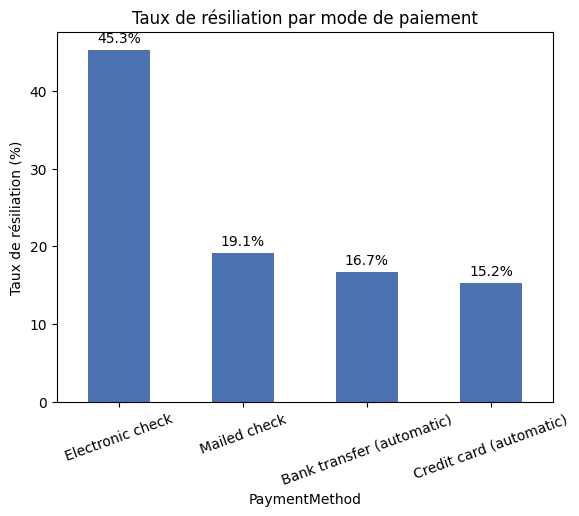

In [38]:
# Du plus élevé au plus faible
order = paiement_churn.sort_values(ascending=False).index

ax = paiement_churn[order].plot(kind="bar", color="#4C72B0")
plt.ylabel("Taux de résiliation (%)")
plt.title("Taux de résiliation par mode de paiement")
plt.xticks(rotation=20)

# Pourcentage écrit au-dessus de chaque barre
for i, valeur in enumerate(paiement_churn[order]):
    plt.text(i, valeur + 1, f"{valeur:.1f}%", ha="center")

plt.show()

Le chèque électronique se détache nettement : 45,3 % de résiliation, soit près de 3 fois plus que la carte bancaire (15,2 %). Les trois autres modes de paiement sont entre 15 et 19 %.

**Prudence :** c'est une association. Les abonnés au chèque électronique sont peut-être aussi plus souvent en contrat mensuel, ce qui expliquerait une partie de l'écart.

Synthèse finale

## Synthèse : réponses aux 4 questions métier

| Question | Réponse chiffrée |
|---|---|
| 1. Le contrat est-il le facteur dominant ? | Oui. Résiliation de 42,7 % en mensuel contre 2,8 % en biannuel : 39,9 points d'écart. |
| 2. À quelle ancienneté le risque est-il maximal ? | Les 6 premiers mois : 52,9 % de résiliation, puis baisse jusqu'à 9,5 % après 4 ans. |
| 3. La fibre optique résilie-t-elle davantage ? | Oui : 41,9 % contre 19,0 % (DSL). Hypothèse : la fibre est plus chère (91,5 contre 58,1 par mois). |
| 4. Quel profil à risque ? | Contrat mensuel + fibre + sans sécurité en ligne + sans support : 1 524 abonnés (21,6 %), 60,7 % de résiliation. |

**Revenu menacé :** 599 abonnés du profil sont encore clients, pour 50 640 par mois.

**Analyse comparative :** le chèque électronique (45,3 %), les seniors (41,7 %) et les abonnés sans conjoint ni personnes à charge résilient davantage. Le genre n'a pas d'effet.

**Recommandations :**
1. Proposer aux abonnés mensuels un avantage pour passer à un engagement annuel.
2. Suivre de près les nouveaux abonnés pendant les 6 premiers mois.
3. Offrir sécurité en ligne et support technique aux abonnés fibre.

**Limites :** ces résultats montrent des associations, pas des causes. La fibre est peut-être liée au prix plutôt qu'au service lui-même